[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Kabir7code/pathsnap/blob/main/notebooks/09_Final_Model_Selection.ipynb)

# 09. Final model selection and final tuning (LightGBM vs Random Forest vs HistGB)
**Run on:** either laptop · **Approx. runtime:** ~1 min on a 4-core laptop

The three strongest classifiers are compared as **complete systems** (classifier + HMM/Viterbi) on **88 development trips**:
- 78 training trips, scored **out-of-fold**: each trip is decoded with probabilities from a model that never saw it.
- The 10 student-test trips.

Each model gets **its own HMM decoder**, tuned on training trips only. The evaluator-test trips are **not used**: the brief forbids using them to choose a model.

This notebook reads the recorded outputs of `scripts/10_final_model_selection.py`, `10b_add_histgb_to_selection.py` and `11_retune_lightgbm_with_hmm.py`. It recomputes the summary tables and the paired bootstrap statistics from the per-trip results, and draws the plots.

**Before running:** the dataset must be in `data/train/<id>/` and `data/student_test/<id>/`, and `pip install -r requirements.txt` done. Run all cells top to bottom (Kernel → Restart & Run All). Every number and plot below is computed when you run it.

**On Google Colab:** run the next cell first. It clones the repo, installs packages and loads `Student_folder.zip` from your Google Drive (`MyDrive/Student_folder.zip`) or asks you to upload it. Locally it does nothing.

In [1]:
# ── Google Colab setup ── (skipped automatically when running locally)
import os, sys, shutil, subprocess, zipfile
if "google.colab" in sys.modules:
    REPO = "/content/pathsnap"
    if not os.path.exists(REPO):
        subprocess.run(["git", "clone", "-q", "https://github.com/Kabir7code/pathsnap.git", REPO], check=True)
    os.chdir(REPO)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "optuna", "lightgbm", "folium", "pyarrow"], check=True)
    if not (os.path.isdir("data/train") and os.path.isdir("data/student_test")):
        # 1) put Student_folder.zip in your Google Drive (MyDrive) -- or 2) upload it when asked
        DATA_ZIP = "/content/drive/MyDrive/Student_folder.zip"
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
        if not os.path.exists(DATA_ZIP):
            from google.colab import files
            print("Student_folder.zip not found in Drive. Please upload it:")
            DATA_ZIP = "/content/" + list(files.upload())[0]
        raw = "/content/_raw"
        shutil.rmtree(raw, ignore_errors=True)
        zipfile.ZipFile(DATA_ZIP).extractall(raw)
        src = next(d for d, sub, _ in os.walk(raw) if "train" in sub and "student_test" in sub)
        os.makedirs("data", exist_ok=True)
        for part in ("train", "student_test"):
            shutil.move(os.path.join(src, part), os.path.join("data", part))
    print("Colab ready:", os.getcwd(), "| train trips:", len(os.listdir("data/train")),
          "| student_test trips:", len(os.listdir("data/student_test")))

In [2]:
import os, sys, warnings
# run from notebooks/ or from the repo root
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT); sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 160)
from pathsnap import nb
from pathsnap.models import make_model
from pathsnap.config import CFG
SEED = CFG["seed"]  # 42: every model and data split uses this seed
print("repo root:", ROOT)

repo root: /home/user/pathsnap_port


## 1. Pre-declared decision rule (fixed before the results were seen)
1. **Primary:** mean per-trip Top-1 after the HMM over the 88 trips. A model wins only if the 95% bootstrap CI of the paired difference excludes 0.
2. If tied, **secondary:** route F1 after the HMM, judged the same way.
3. If still tied: probability quality (log loss), inference speed and model size.

In [3]:
import json
S = "results/08_final_model_selection"
per = pd.read_csv(f"{S}/per_trip_all_models.csv", dtype={"trip": str})
own = per[per.decoder == "own"].copy()
own["set"] = own.split.map({"train_oof": "78 training trips (OOF)", "student_test": "10 student-test trips"})
cols = ["cls_top1", "hmm_top1", "cls_route_f1", "hmm_route_f1", "cls_continuity", "hmm_continuity"]
tab = pd.concat([own.groupby(["set", "model"])[cols].mean(),
                 own.assign(set="ALL 88 development trips").groupby(["set", "model"])[cols].mean()])
tab.columns = ["Top-1 classifier", "Top-1 + HMM", "route F1 classifier", "route F1 + HMM", "continuity classifier", "continuity + HMM"]
tab.round(4)

Top-1 classifier  Top-1 + HMM  route F1 classifier  route F1 + HMM  continuity classifier  continuity + HMM
set                      model                                                                                                                        
10 student-test trips    HistGB                      0.8964       0.9492               0.7766          0.9579                 0.9286            0.9781
                         LightGBM (tuned)            0.9017       0.9491               0.7865          0.9583                 0.9329            0.9776
                         Random Forest               0.8937       0.9482               0.7650          0.9569                 0.9254            0.9778
78 training trips (OOF)  HistGB                      0.8855       0.9326               0.7678          0.9390                 0.9152            0.9698
                         LightGBM (tuned)            0.8868       0.9316               0.7750          0.9388                 0.9181            0.9698
                         Random Forest               0.8822       0.9302               0.7581          0.9378                 0.9122            0.9696
ALL 88 development trips HistGB                      0.8867       0.9345               0.7688          0.9412                 0.9167            0.9707
                         LightGBM (tuned)            0.8884       0.9336               0.7763          0.9410                 0.9198            0.9707
                         Random Forest               0.8835       0.9322               0.7589          0.9400                 0.9137            0.9705

## 2. Accuracy before vs after the HMM

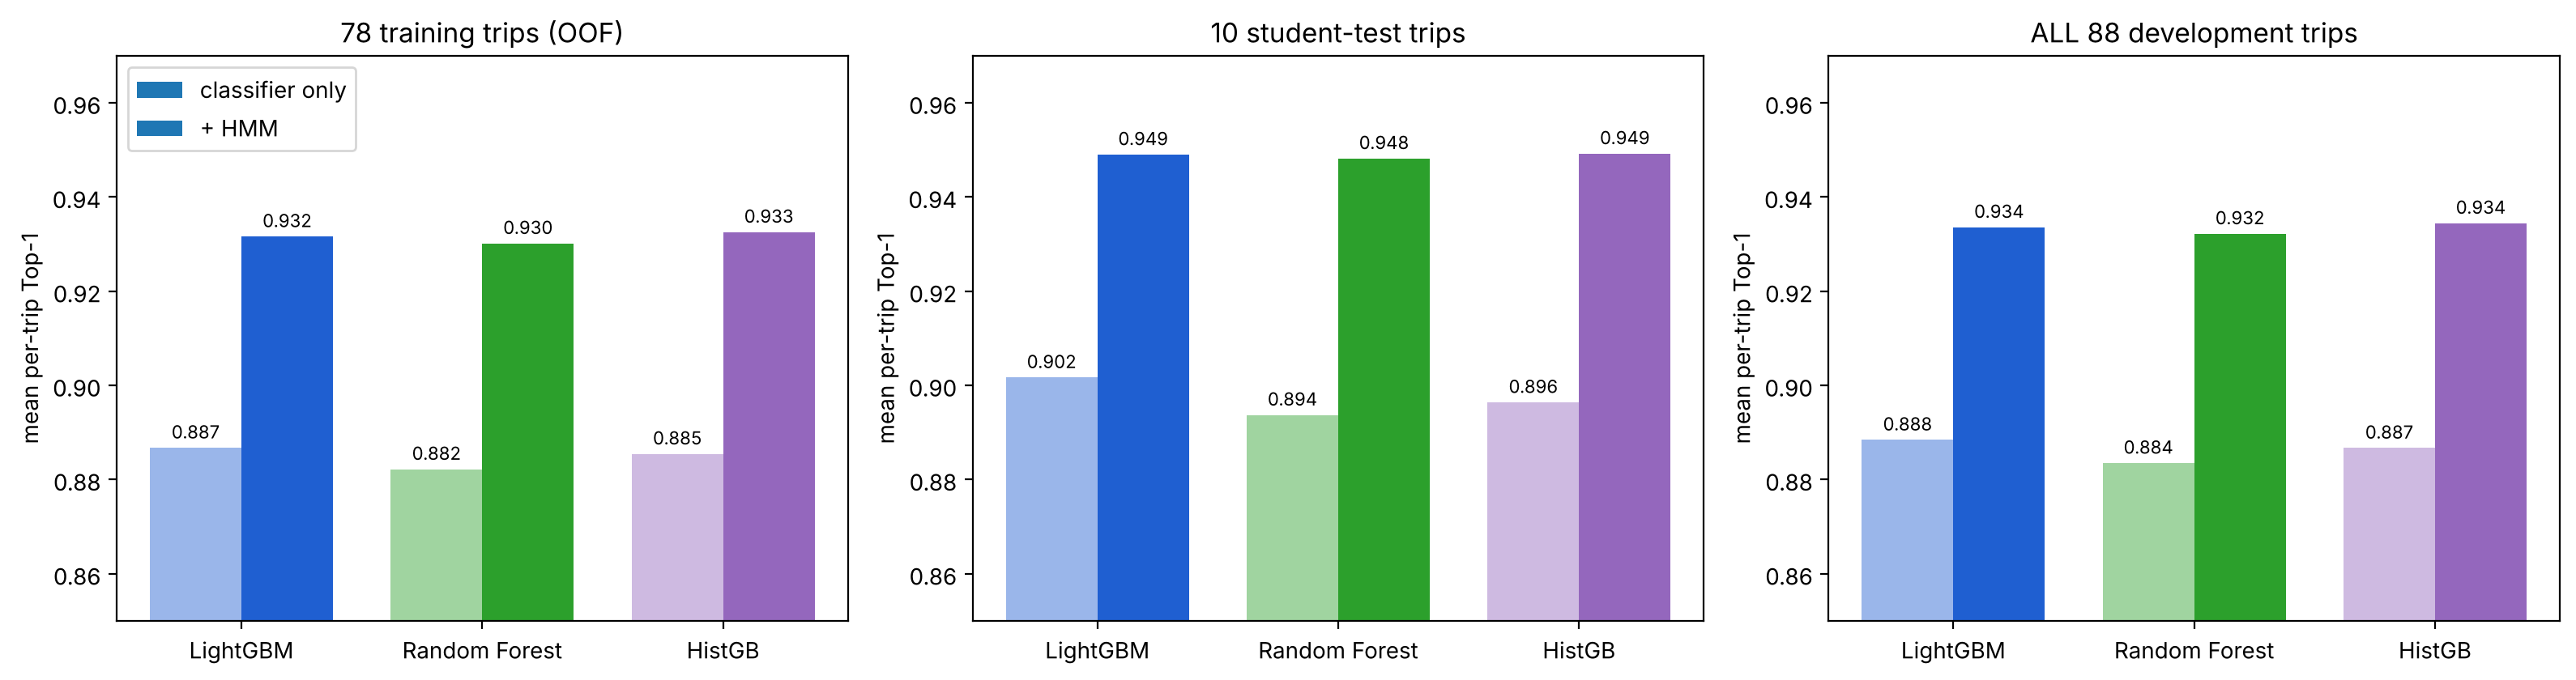

In [4]:
c = {"LightGBM (tuned)": "#1f5fd1", "Random Forest": "#2ca02c", "HistGB": "#9467bd"}
fig, axs = plt.subplots(1, 3, figsize=(16, 4.3))
for ax, sp in zip(axs, ["78 training trips (OOF)", "10 student-test trips", "ALL 88 development trips"]):
    t = tab.loc[sp]
    for i, m in enumerate(c):
        for j, (k, al) in enumerate([("Top-1 classifier", .45), ("Top-1 + HMM", 1)]):
            v = t.loc[m, k]; x = i + (j - .5) * .38
            ax.bar(x, v, .38, color=c[m], alpha=al); ax.text(x, v + .002, f"{v:.3f}", ha="center", fontsize=8)
    ax.set_xticks(range(3), ["LightGBM", "Random Forest", "HistGB"]); ax.set(title=sp, ylim=(0.85, 0.97), ylabel="mean per-trip Top-1")
axs[0].bar([], [], color="grey", alpha=.45, label="classifier only"); axs[0].bar([], [], color="grey", label="+ HMM"); axs[0].legend(loc="upper left")
fig.tight_layout(); nb.show(fig)

## 3. Is any difference real? Paired bootstrap 95% CI over the 88 trips

,comparison,metric,mean diff,CI low,CI high,significant,Random Forest better (trips),other better (trips),HistGB better (trips)
0,Random Forest − LightGBM (tuned),hmm_top1,-0.0014,-0.0038,0.0007,False,35.0,36,NaN
1,Random Forest − LightGBM (tuned),hmm_route_f1,-0.0010,-0.0016,-0.0005,True,11.0,38,NaN
2,Random Forest − LightGBM (tuned),cls_top1,-0.0049,-0.0064,-0.0034,True,15.0,70,NaN
3,Random Forest − LightGBM (tuned),cls_route_f1,-0.0174,-0.0218,-0.0133,True,9.0,76,NaN
4,HistGB − LightGBM (tuned),hmm_top1,0.0009,-0.0008,0.0032,False,NaN,36,36.0
5,HistGB − LightGBM (tuned),hmm_route_f1,0.0002,-0.0004,0.0008,False,NaN,16,21.0
6,HistGB − LightGBM (tuned),cls_top1,-0.0017,-0.0029,-0.0004,True,NaN,55,25.0
7,HistGB − LightGBM (tuned),cls_route_f1,-0.0075,-0.0111,-0.0039,True,NaN,59,24.0


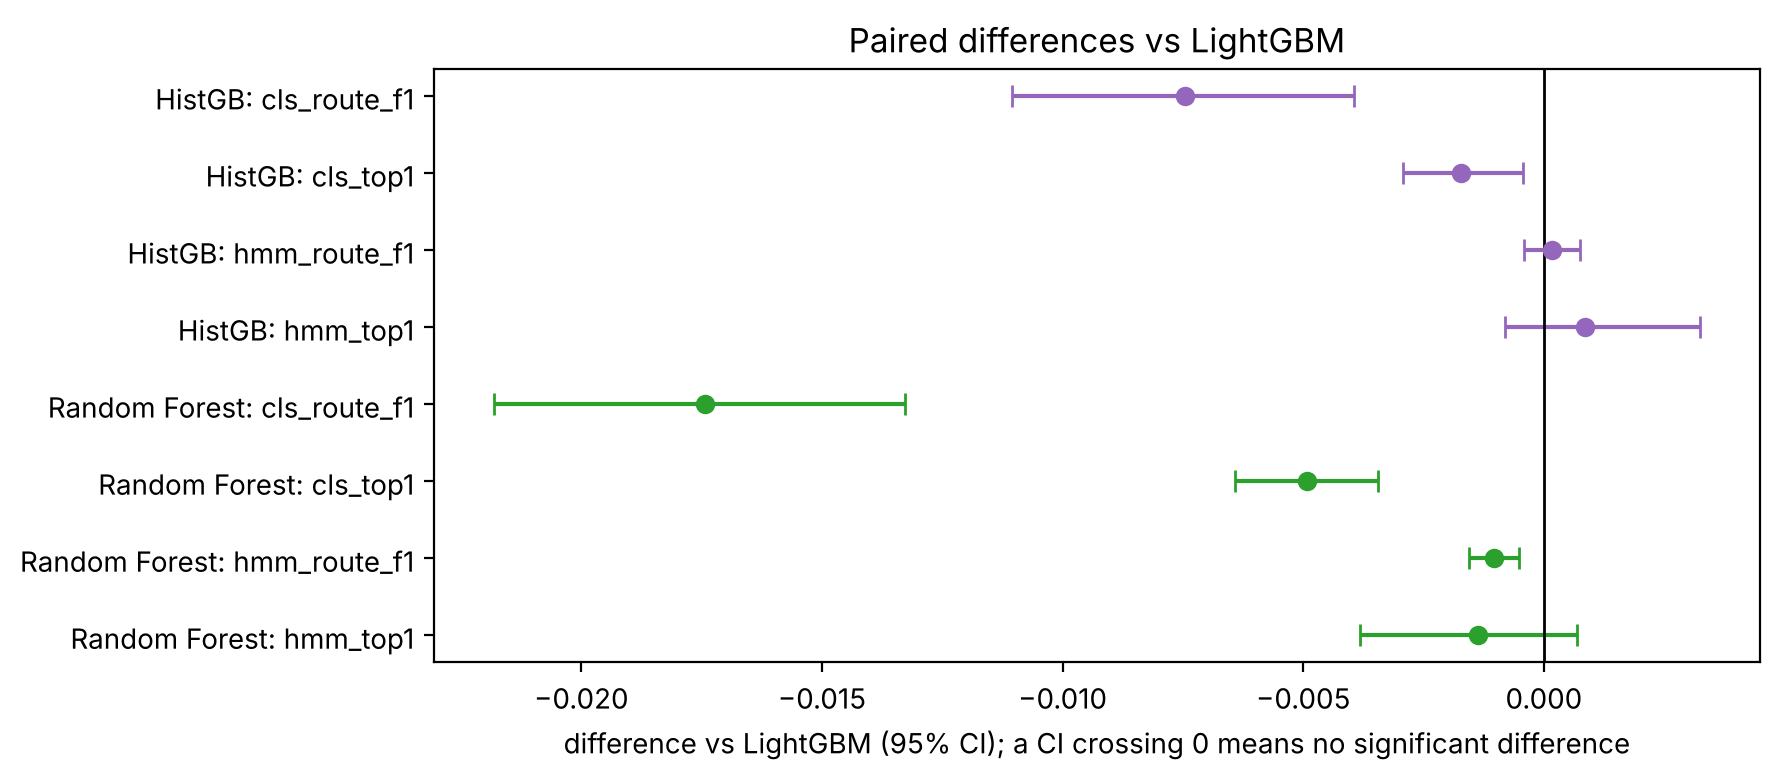

In [5]:
def paired(a_name, b_name, metric):
    a = own[own.model == a_name].set_index(["split", "trip"])[metric]
    b = own[own.model == b_name].set_index(["split", "trip"])[metric].reindex(a.index)
    d = (b - a).to_numpy(); bo = np.random.default_rng(SEED).choice(d, (10_000, len(d))).mean(axis=1)
    lo, hi = np.percentile(bo, [2.5, 97.5])
    return {"comparison": f"{b_name} − {a_name}", "metric": metric, "mean diff": d.mean(), "CI low": lo, "CI high": hi,
            "significant": not (lo <= 0 <= hi), f"{b_name} better (trips)": int((d > 0).sum()), "other better (trips)": int((d < 0).sum())}
rows = [paired(a, b, m) for a, b in [("LightGBM (tuned)", "Random Forest"), ("LightGBM (tuned)", "HistGB")]
        for m in ["hmm_top1", "hmm_route_f1", "cls_top1", "cls_route_f1"]]
st = pd.DataFrame(rows); display(st.round(4))
fig, ax = plt.subplots(figsize=(9, 4))
for i, r in st.iterrows():
    ax.errorbar(r["mean diff"], i, xerr=[[r["mean diff"] - r["CI low"]], [r["CI high"] - r["mean diff"]]], fmt="o", capsize=4,
                color="#2ca02c" if "Random" in r.comparison else "#9467bd")
ax.axvline(0, color="k", lw=1); ax.set_yticks(range(len(st)), [f"{r.comparison.split(' −')[0]}: {r.metric}" for r in st.itertuples()])
ax.set(xlabel="difference vs LightGBM (95% CI); a CI crossing 0 means no significant difference", title="Paired differences vs LightGBM")
fig.tight_layout(); nb.show(fig)

## 4. Practical criteria: probability quality, speed, size

In [6]:
dec = json.load(open(f"{S}/decision.json"))
pd.DataFrame(dec["probability_quality_and_cost"]).T.round(4)

,oof_log_loss,test_log_loss,test_infer_ms_per_point,model_file_mb
LightGBM (tuned),0.1110,0.1045,0.0403,1.6930
Random Forest,0.1160,0.1109,0.0215,18.1208
HistGB,0.1162,0.1084,0.0067,0.1921


## 5. Decision
- **After the HMM, all three are statistically tied on Top-1.**
- **LightGBM is significantly better than Random Forest on route F1 after the HMM.**
- LightGBM is significantly better than both before the HMM, as a classifier on its own.
- It also has the best-calibrated probabilities (lowest log loss), which matters because the HMM uses them directly.

**Final model: LightGBM.**

## 6. Final tuning of LightGBM with the HMM in the loop

In [7]:
T = "results/09_final_tuning_lightgbm_with_hmm"
tv = pd.read_csv(f"{T}/tuned_vs_untuned_lightgbm.csv").set_index("variant")
d7 = json.load(open(f"{T}/decision_lightgbm.json"))
print("objective:", d7["search"]["objective"], "| trials:", d7["search"]["trials"])
print("best params:", d7["search"]["best_params"])
print(f"re-tuned − current, Top-1 + HMM over 88 trips: {d7['tuned_minus_untuned_dev88_hmm_top1']:+.4f}  95% CI {np.round(d7['ci95'], 4)}")
print("deployed:", d7["deployed_variant"])
tv[["cv_macro_f1", "test_top1", "test_log_loss", "test_cls_top1_trip_mean", "test_hmm_top1_trip_mean", "dev88_hmm_top1", "dev88_hmm_route_f1"]].T.round(4)

objective: mean per-trip HMM Top-1, 3-fold OOF on training trips <= 3000 points | trials: 20
best params: {'n_estimators': 500, 'learning_rate': 0.023840834569139942, 'num_leaves': 138, 'min_child_samples': 82, 'subsample': 0.949699467469508, 'colsample_bytree': 0.9382196066725687, 'reg_lambda': 0.043683124270273606}
re-tuned − current, Top-1 + HMM over 88 trips: +0.0005  95% CI [-0.0027  0.0048]
deployed: current (tuned for classifier F1)


variant,current (tuned for classifier F1),re-tuned (HMM objective)
cv_macro_f1,0.9279,0.9276
test_top1,0.8859,0.8868
test_log_loss,0.1040,0.1037
test_cls_top1_trip_mean,0.9017,0.9027
test_hmm_top1_trip_mean,0.9491,0.9472
dev88_hmm_top1,0.9336,0.9342
dev88_hmm_route_f1,0.9410,0.9407


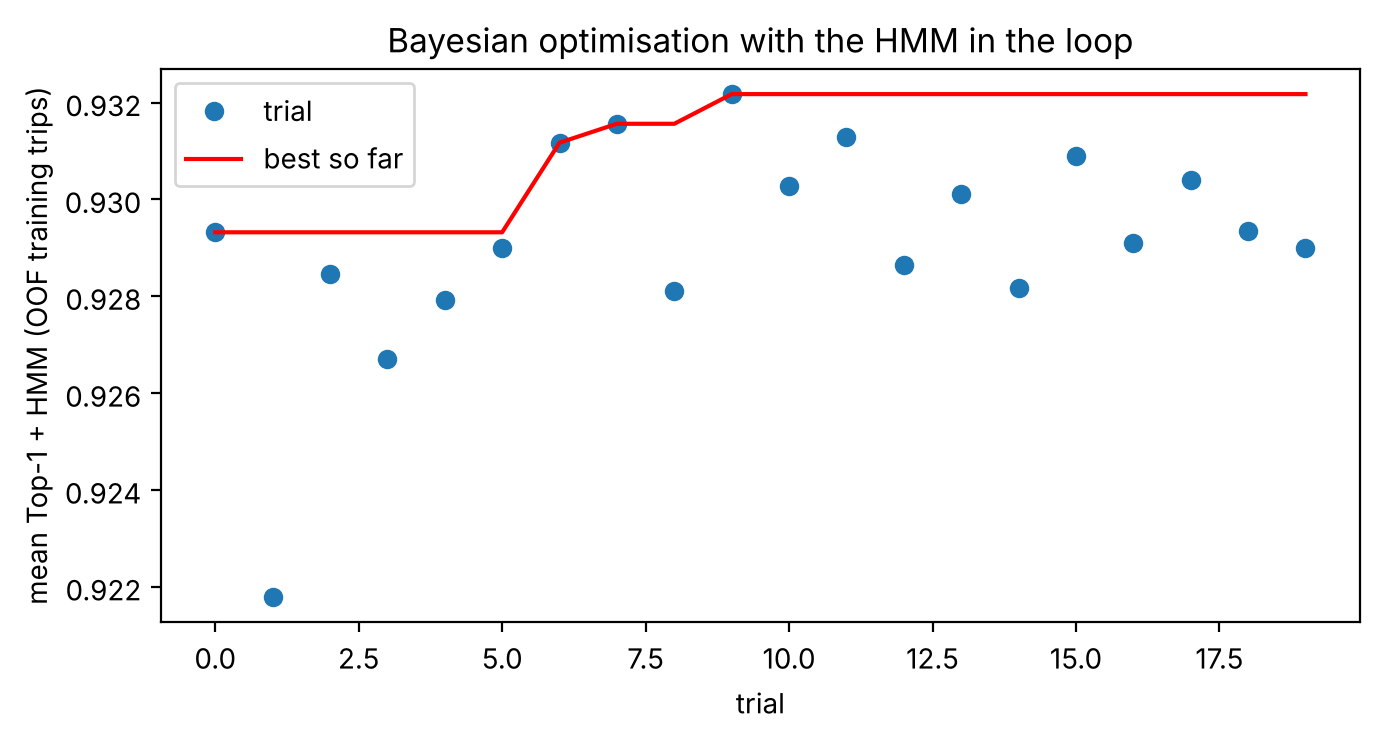

In [8]:
tri = pd.read_csv(f"{T}/trials_lightgbm.csv")
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(tri.number, tri.value, "o", label="trial"); ax.plot(tri.number, tri.value.cummax(), "r-", label="best so far")
ax.set(xlabel="trial", ylabel="mean Top-1 + HMM (OOF training trips)", title="Bayesian optimisation with the HMM in the loop"); ax.legend()
fig.tight_layout(); nb.show(fig)